# Field Shift · v2 models with the Niño 1+2 index

**Nothing from Phases 1–3 is modified.** v1 (`artifacts/final_model/`) is loaded read-only as the reference; this notebook
writes only to `artifacts/v2_nino_models/`. The rules were written and committed before this notebook was run:
[`docs/ML_V2_NINO_MODELS.md` §3](../../docs/ML_V2_NINO_MODELS.md).

- Training 1998–2017 (fit 1998–2015, early stopping 2016–2017, refit on all 1998–2017), same hyperparameters as v1.
- **Validation 2018–2022 decides.** 2023–2025 is a second look only (already seen by the Phase 3 test).
- The ERA5 GRIB received is not used (hourly product, one hour per day, 1998–2004 only; see the doc §2).

## 1. Setup and the pre-registered rules

In [1]:
import sys, json, math, platform, time
from pathlib import Path
import numpy as np, pandas as pd, xgboost as xgb
import matplotlib.pyplot as plt
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from fs_ml import data as D, features as F, evaluate as E, enso as N
from fs_ml.predict import load, season_of

SEED, N_BOOT, NOMINAL = 42, 1000, 0.90
pd.set_option("display.width", 170, "display.max_columns", 30)
SPLITS = {"training": (1998, 2017), "validation": (2018, 2022), "testing": (2023, 2025)}
INTERNAL = {"fit": (1998, 2015), "early_stopping": (2016, 2017)}
CAL, CHK = (2018, 2020), (2021, 2022)
ART = ML_DIR / "artifacts" / "v2_nino_models"; ART.mkdir(parents=True, exist_ok=True)
NAMES = ["sm_root_monthly", "ndvi_quarterly"]
NEW = {"sm_root_monthly": N.MONTHLY_FEATURES, "ndvi_quarterly": N.QUARTERLY_FEATURES}
CLIM_KEYS = {"sm_root_monthly": (["cell_id", "month"], "month"), "ndvi_quarterly": (["cell_id", "quarter"], "quarter")}
LAG = {"sm_root_monthly": "sm_root_m3m3_lag1", "ndvi_quarterly": "ndvi_lag1"}

# Same thresholds as Phase 1 §10 (docs/ML_PHASE1_TRAINING.md). Written before training; do not edit.
CRITERIA = {"sm_root_monthly": {"A_skill_min": 0.20, "C_rmse_max": 0.04, "D_abs_bias_max": 0.01},
            "ndvi_quarterly": {"A_skill_min": 0.10, "C_rmse_max": None, "D_abs_bias_max": 0.03},
            "F_coverage_90": (0.87, 0.93)}

V1 = {n: load(n) for n in NAMES}
V1_SHA = {n: D.sha256(ML_DIR / "artifacts" / "final_model" / n / "model.ubj") for n in NAMES}
assert all(V1_SHA[n] == V1[n]["card"]["sha256"] for n in NAMES), "v1 package changed"
NINO, NINO_INFO = N.load_nino12()
print(json.dumps(NINO_INFO, indent=1)); print({n: V1_SHA[n][:16] for n in NAMES}, "| xgboost", xgb.__version__)

{
 "file": "nino12.long.anom.csv",
 "sha256": "94b7f5fb8fb6d014a7280b3dcd7ececf795a714085c9838b26fd177e4748fba7",
 "header": "Date,   NINA12  missing value -99.99 https://psl.noaa.gov/data/timeseries/month/",
 "first": "1870-01-01",
 "last": "2026-09-01",
 "months": 1881,
 "missing_coded_values": 3,
 "gaps": 0
}
{'sm_root_monthly': 'a4bbaf1397c43e2c', 'ndvi_quarterly': 'effe57ea2506d509'} | xgboost 3.4.1


## 2. The Niño 1+2 index in each period

In [2]:
nm = N.monthly_index(NINO); nm["year"] = nm.date.dt.year
rows = []
for p, (a, b) in SPLITS.items():
    s = nm[nm.year.between(a, b)].nino12_anom
    rows.append({"period": f"{p} {a}-{b}", "months": len(s), "missing": int(s.isna().sum()), "min": s.min(), "max": s.max(),
                 "months_above_+1.0": int((s > 1).sum()), "months_above_+2.0": int((s > 2).sum())})
display(pd.DataFrame(rows).round(2))
peaks = nm[nm.year.between(1998, 2025) & (nm.nino12_anom > 1.5)].groupby("year").nino12_anom.agg(["size", "max"]).rename(columns={"size": "months_above_1.5"})
print("Years with months above +1.5 °C (coastal El Niño conditions):"); display(peaks.round(2))
print("2026 is not used (no complete data yet). For reference, Niño 1+2 in Sep 2026:", float(nm[nm.date == "2026-09-01"].nino12_anom.iloc[0]))

,period,months,missing,min,max,months_above_+1.0,months_above_+2.0
0,training 1998-2017,240,0,-1.95,3.55,22,12
1,validation 2018-2022,60,0,-1.37,0.79,0,0
2,testing 2023-2025,36,0,-0.80,2.55,11,5


Years with months above +1.5 °C (coastal El Niño conditions):


,months_above_1.5,max
year,,
1998,6,3.55
2015,8,2.48
2016,1,1.82
2017,1,1.56
2023,8,2.55


2026 is not used (no complete data yet). For reference, Niño 1+2 in Sep 2026: 3.85


Training holds two strong events (1998, with the end of the 1997–98 El Niño, and the 2017 coastal El Niño) plus 2015–16.
Validation 2018–2022 is calm. Testing holds the 2023 coastal El Niño.

## 3. Tables for the three periods (same `fs_ml` code as every phase, plus the index)

In [3]:
def build(load_years, suffix):
    monthly, _ = D.load_gee_monthly(load_years); veg, _ = D.load_gee_quarterly(load_years)
    pw = {p: D.load_power(f"power_{p}{suffix}", load_years)[0] for p in ["t2m", "rh2m", "ws2m", "allsky"]}
    merra = pw["t2m"].merge(pw["rh2m"], on=["power_lat", "power_lon", "date"]).merge(pw["ws2m"], on=["power_lat", "power_lon", "date"])
    gaez = {k: D.load_gaez(k)[0] for k in F.GAEZ_FEATURES}
    cells = F.static_cells(D.cells_from_ids(monthly.cell_id), gaez, merra[["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True),
                           pw["allsky"][["power_lat", "power_lon"]].drop_duplicates().reset_index(drop=True))
    mp = F.build_monthly_panel(monthly, cells, merra, pw["allsky"]); qp = F.build_quarterly_panel(mp, veg)
    mp, qp = N.add_to_monthly(mp, NINO), N.add_to_quarterly(qp, NINO)
    extra = pd.DataFrame({"cell_id": cells.cell_id.to_numpy(), "block": np.asarray(E.spatial_blocks(cells.lat, cells.lon)), "province": np.asarray(D.provinces_of(cells))})
    mp, qp = mp.merge(extra, on="cell_id", how="left"), qp.merge(extra, on="cell_id", how="left")
    return {"sm_root_monthly": mp, "ndvi_quarterly": qp}

T = {"training": build((1998, 2017), ""), "validation": build((2017, 2022), "_2018_2022"), "testing": build((2022, 2025), "_2023_2025")}
def rows_of(period, name):
    df = T[period][name]; t = V1[name]["card"]["target"]["column"]
    return df[df.year.between(*SPLITS[period]) & df[t].notna()].reset_index(drop=True)
R = {p: {n: rows_of(p, n) for n in NAMES} for p in SPLITS}
print({p: {n: len(R[p][n]) for n in NAMES} for p in SPLITS})
print("missing Niño inputs:", {p: {n: int(R[p][n][NEW[n]].isna().sum().sum()) for n in NAMES} for p in SPLITS})

{'training': {'sm_root_monthly': 750240, 'ndvi_quarterly': 91224}, 'validation': {'sm_root_monthly': 187560, 'ndvi_quarterly': 50477}, 'testing': {'sm_root_monthly': 112536, 'ndvi_quarterly': 30056}}
missing Niño inputs: {'training': {'sm_root_monthly': 0, 'ndvi_quarterly': 0}, 'validation': {'sm_root_monthly': 0, 'ndvi_quarterly': 0}, 'testing': {'sm_root_monthly': 0, 'ndvi_quarterly': 0}}


## 4. Train v2 (same protocol and hyperparameters as v1)

In [4]:
V1_PARAMS = V1["sm_root_monthly"]["card"]["hyperparameters"]
BASE = {k: v for k, v in V1_PARAMS.items() if k != "n_estimators"} | {"n_estimators": 5000, "early_stopping_rounds": 100}
V2 = {}
for n in NAMES:
    t = V1[n]["card"]["target"]["column"]; feats = V1[n]["features"] + NEW[n]; d = R["training"][n]
    fit, es = d[d.year.between(*INTERNAL["fit"])], d[d.year.between(*INTERNAL["early_stopping"])]
    t0 = time.time()
    m1 = xgb.XGBRegressor(**BASE).fit(fit[feats], fit[t], eval_set=[(es[feats], es[t])], verbose=False)
    best = m1.best_iteration + 1
    p2 = {k: v for k, v in BASE.items() if k != "early_stopping_rounds"} | {"n_estimators": best}
    m2 = xgb.XGBRegressor(**p2).fit(d[feats], d[t], verbose=False)
    es_rmse = E.regression_metrics(es[t], m1.predict(es[feats], iteration_range=(0, best)))["RMSE"]
    V2[n] = {"model": m2, "features": feats, "trees": best, "params": p2, "internal_es_rmse": es_rmse,
             "bounds": E.feature_bounds(d[feats]), "seconds": round(time.time() - t0, 1)}
    print(f"{n}: trees {best} (v1 {V1[n]['card']['trees']}), internal 2016-2017 RMSE {es_rmse:.4f}, {V2[n]['seconds']} s")

sm_root_monthly: trees 2171 (v1 1122), internal 2016-2017 RMSE 0.0212, 47.2 s


ndvi_quarterly: trees 107 (v1 89), internal 2016-2017 RMSE 0.1448, 0.7 s


## 5. Validation 2018–2022 (this decides)

In [5]:
def preds(period, n):
    r = R[period][n]; t = V1[n]["card"]["target"]["column"]
    keys, season = CLIM_KEYS[n]
    clim = E.predict_climatology(E.climatology(R["training"][n], t, keys, season), r)
    pers = np.where(r[LAG[n]].isna(), clim, r[LAG[n]])
    return r, r[t].to_numpy(), {"v2": V2[n]["model"].predict(r[V2[n]["features"]]), "v1": V1[n]["model"].predict(r[V1[n]["features"]]),
                                "climatology": clim, "persistence": pers}

VAL, CI = {}, {}
for n in NAMES:
    r, y, p = preds("validation", n); VAL[n] = (r, y, p)
    CI[n] = E.block_bootstrap(y, p, r.block.to_numpy(), reference="v2", n_boot=N_BOOT, seed=SEED)
    print(f"\n=== {n}: validation 2018-2022, n = {len(y)}"); display(CI[n].round(4))


=== sm_root_monthly: validation 2018-2022, n = 187560


,model,metric,value,ci_low,ci_high
0,v2,MAE,0.0073,0.0062,0.0084
1,v2,RMSE,0.0126,0.0111,0.0141
2,v2,R2,0.9858,0.9812,0.9892
3,v2,bias,-0.0001,-0.0005,0.0002
4,v2,skill vs v1,-0.0094,-0.0308,0.0101
5,v2,skill vs climatology,0.6008,0.5671,0.6326
6,v2,skill vs persistence,0.5144,0.4738,0.5497
7,v1,MAE,0.0073,0.0061,0.0084
8,v1,RMSE,0.0125,0.0110,0.0139
9,v1,R2,0.9860,0.9813,0.9895



=== ndvi_quarterly: validation 2018-2022, n = 50477


,model,metric,value,ci_low,ci_high
0,v2,MAE,0.0755,0.0702,0.0803
1,v2,RMSE,0.1044,0.0980,0.1103
2,v2,R2,0.6535,0.5922,0.7085
3,v2,bias,-0.0032,-0.0100,0.0031
4,v2,skill vs v1,-0.0131,-0.0215,-0.0050
5,v2,skill vs climatology,0.1685,0.0864,0.2469
6,v2,skill vs persistence,0.3321,0.2754,0.3764
7,v1,MAE,0.0747,0.0698,0.0794
8,v1,RMSE,0.1031,0.0968,0.1089
9,v1,R2,0.6624,0.6021,0.7158


In [6]:
DECISION, CRIT = {}, {}
for n in NAMES:
    r, y, p = VAL[n]; c = CRITERIA[n]; t = CI[n].set_index(["model", "metric"])
    rm = {k: E.regression_metrics(y, v)["RMSE"] for k, v in p.items() if k in ("climatology", "persistence")}
    best = min(rm, key=rm.get)
    sk, rmse, bias = t.loc[("v2", f"skill vs {best}")], t.loc[("v2", "RMSE")], t.loc[("v2", "bias")]
    def worst(col):
        out = {}
        for g, m in r.groupby(col).groups.items():
            if g == "outside": continue
            out[g] = E.skill(E.regression_metrics(y[m], p["v2"][m])["RMSE"], E.regression_metrics(y[m], p[best][m])["RMSE"])
        return min(out.values())
    wy, wp = worst("year"), worst("province")
    yr = r.year.to_numpy(); res = p["v2"] - y
    h = E.conformal_halfwidth(res[(yr >= CAL[0]) & (yr <= CAL[1])], NOMINAL); chk = (yr >= CHK[0]) & (yr <= CHK[1])
    cov, _, _ = E.coverage_ci(np.abs(res[chk]) <= h, r.block.to_numpy()[chk])
    lo, hi = CRITERIA["F_coverage_90"]
    rows = [("A", f"skill vs {best} >= {c['A_skill_min']}", f"{sk.value:.3f} [{sk.ci_low:.3f}, {sk.ci_high:.3f}]", sk.value >= c["A_skill_min"]),
            ("B", "lower 95% CI of that skill > 0", f"{sk.ci_low:.3f}", sk.ci_low > 0),
            ("C", f"RMSE <= {c['C_rmse_max']}" if c["C_rmse_max"] else "RMSE (report only)", f"{rmse.value:.4f} [{rmse.ci_low:.4f}, {rmse.ci_high:.4f}]",
             (rmse.value <= c["C_rmse_max"]) if c["C_rmse_max"] else None),
            ("D", f"|bias| <= {c['D_abs_bias_max']}", f"{bias.value:.4f} [{bias.ci_low:.4f}, {bias.ci_high:.4f}]", abs(bias.value) <= c["D_abs_bias_max"]),
            ("E", "skill >= 0 in every year and province", f"worst year {wy:.3f}, worst province {wp:.3f}", min(wy, wp) >= 0),
            ("F", f"90% coverage 2021-2022 in [{lo}, {hi}]", f"{cov:.3f} (width ±{h:.4f})", lo <= cov <= hi)]
    CRIT[n] = pd.DataFrame(rows, columns=["criterion", "rule", "result", "pass"])
    vs = t.loc[("v2", "skill vs v1")]
    passes = bool(CRIT[n]["pass"].dropna().all())
    verdict = ("better than v1 on Validation" if vs.ci_low > 0 else "worse than v1: rejected" if vs.ci_high < 0
               else "no clear difference on Validation: decision waits for 2026")
    if not passes: verdict = "fails A-F: rejected"
    DECISION[n] = {"passes_A_F": passes, "skill_vs_v1": [float(vs.value), float(vs.ci_low), float(vs.ci_high)],
                   "rmse_v2": float(t.loc[("v2", "RMSE")].value), "rmse_v1": float(t.loc[("v1", "RMSE")].value), "verdict": verdict}
    print(f"\n=== {n}"); display(CRIT[n])
    print(f"skill v2 vs v1: {vs.value:.3f} [{vs.ci_low:.3f}, {vs.ci_high:.3f}]  ->  {verdict}")


=== sm_root_monthly


,criterion,rule,result,pass
0,A,skill vs persistence >= 0.2,"0.514 [0.474, 0.550]",True
1,B,lower 95% CI of that skill > 0,0.474,True
2,C,RMSE <= 0.04,"0.0126 [0.0111, 0.0141]",True
3,D,|bias| <= 0.01,"-0.0001 [-0.0005, 0.0002]",True
4,E,skill >= 0 in every year and province,"worst year 0.458, worst province 0.314",True
5,F,"90% coverage 2021-2022 in [0.87, 0.93]",0.885 (width ±0.0178),True


skill v2 vs v1: -0.009 [-0.031, 0.010]  ->  no clear difference on Validation: decision waits for 2026

=== ndvi_quarterly


,criterion,rule,result,pass
0,A,skill vs climatology >= 0.1,"0.169 [0.086, 0.247]",True
1,B,lower 95% CI of that skill > 0,0.086,True
2,C,RMSE (report only),"0.1044 [0.0980, 0.1103]",None
3,D,|bias| <= 0.03,"-0.0032 [-0.0100, 0.0031]",True
4,E,skill >= 0 in every year and province,"worst year 0.061, worst province -0.016",False
5,F,"90% coverage 2021-2022 in [0.87, 0.93]",0.881 (width ±0.1690),True


skill v2 vs v1: -0.013 [-0.021, -0.005]  ->  fails A-F: rejected


## 6. Second look at 2023–2025 (already seen by Phase 3: report only)

In [7]:
TEST, TCI = {}, {}
for n in NAMES:
    r, y, p = preds("testing", n); TEST[n] = (r, y, p)
    TCI[n] = E.block_bootstrap(y, {k: p[k] for k in ("v2", "v1")}, r.block.to_numpy(), reference="v2", n_boot=N_BOOT, seed=SEED)
    print(f"\n=== {n}: 2023-2025, n = {len(y)}"); display(TCI[n].round(4))


=== sm_root_monthly: 2023-2025, n = 112536


,model,metric,value,ci_low,ci_high
0,v2,MAE,0.0110,0.0100,0.0120
1,v2,RMSE,0.0185,0.0172,0.0199
2,v2,R2,0.9664,0.9594,0.9718
3,v2,bias,-0.0027,-0.0034,-0.0021
4,v2,skill vs v1,0.0653,0.0394,0.0916
5,v1,MAE,0.0113,0.0103,0.0123
6,v1,RMSE,0.0198,0.0185,0.0211
7,v1,R2,0.9615,0.9541,0.9676
8,v1,bias,-0.0030,-0.0036,-0.0024



=== ndvi_quarterly: 2023-2025, n = 30056


,model,metric,value,ci_low,ci_high
0,v2,MAE,0.0888,0.0849,0.0922
1,v2,RMSE,0.1206,0.1153,0.1255
2,v2,R2,0.5673,0.5252,0.6091
3,v2,bias,-0.0242,-0.0298,-0.0184
4,v2,skill vs v1,0.0447,0.0245,0.0656
5,v1,MAE,0.0938,0.0898,0.0973
6,v1,RMSE,0.1262,0.1208,0.1308
7,v1,R2,0.5258,0.4774,0.5723
8,v1,bias,-0.0264,-0.0322,-0.0204


In [8]:
def period_key(r):
    return r.date if "date" in r else pd.to_datetime(dict(year=r.year, month=(r.quarter - 1) * 3 + 1, day=1))
FOCUS = {"sm_root_monthly": [("2023", lambda r: r.year == 2023), ("Mar 2023", lambda r: (r.year == 2023) & (r.month == 3)),
                             ("May 2024", lambda r: (r.year == 2024) & (r.month == 5)), ("2024", lambda r: r.year == 2024), ("2025", lambda r: r.year == 2025)],
         "ndvi_quarterly": [("2023", lambda r: r.year == 2023), ("Q2 2023", lambda r: (r.year == 2023) & (r.quarter == 2)),
                            ("2024", lambda r: r.year == 2024), ("2025", lambda r: r.year == 2025)]}
FOC = []
for n in NAMES:
    r, y, p = TEST[n]
    for label, f in FOCUS[n]:
        m = f(r).to_numpy()
        for k in ("v1", "v2"):
            met = E.regression_metrics(y[m], p[k][m]); FOC.append({"model": n, "period": label, "version": k, "n": met["n"], "RMSE": met["RMSE"], "bias": met["bias"]})
FOC = pd.DataFrame(FOC); FOC.pivot_table(index=["model", "period"], columns="version", values=["RMSE", "bias"], sort=False).round(4)

RMSE            bias        
version                       v1      v2      v1      v2
model           period                                  
sm_root_monthly 2023      0.0231  0.0200 -0.0046 -0.0041
                Mar 2023  0.0533  0.0393 -0.0367 -0.0245
                May 2024  0.0266  0.0270 -0.0178 -0.0187
                2024      0.0186  0.0189 -0.0019 -0.0019
                2025      0.0172  0.0164 -0.0025 -0.0021
ndvi_quarterly  2023      0.1417  0.1253 -0.0591 -0.0440
                2024      0.1153  0.1120  0.0167  0.0132
                2025      0.1199  0.1242 -0.0374 -0.0427
                Q2 2023   0.2209  0.1822 -0.1524 -0.1019

In [9]:
OOD = {}
for n in NAMES:
    r = R["testing"][n]; b = V2[n]["bounds"]
    OOD[n] = {c: {"share_outside_p01_p99": float(((r[c] < b[c]["p01"]) | (r[c] > b[c]["p99"])).mean()),
                  "share_outside_min_max": float(((r[c] < b[c]["min"]) | (r[c] > b[c]["max"])).mean())} for c in NEW[n]}
    OOD[n]["any_input_outside_p01_p99"] = float(E.out_of_range(r[V2[n]["features"]], b).mean())
print(json.dumps(OOD, indent=1))

{
 "sm_root_monthly": {
  "nino12_anom": {
   "share_outside_p01_p99": 0.0,
   "share_outside_min_max": 0.0
  },
  "nino12_anom_lag1": {
   "share_outside_p01_p99": 0.0,
   "share_outside_min_max": 0.0
  },
  "nino12_anom_3m": {
   "share_outside_p01_p99": 0.0,
   "share_outside_min_max": 0.0
  },
  "any_input_outside_p01_p99": 0.20644060567285136
 },
 "ndvi_quarterly": {
  "q_nino12_anom": {
   "share_outside_p01_p99": 0.0,
   "share_outside_min_max": 0.0
  },
  "q_nino12_anom_lag1": {
   "share_outside_p01_p99": 0.0,
   "share_outside_min_max": 0.0
  },
  "any_input_outside_p01_p99": 0.18438914027149322
 }
}


### 6.1 Error range with monthly recalibration (same ACI method as the v2 intervals experiment)

Width = 90 % quantile of the absolute errors of the last 36 months (12 quarters), same season; step γ chosen on
Validation only (history 2018–2019, run over 2020–2022), then the run continues through 2023–2025.

In [10]:
GAMMAS, WINDOW = [0.0, 0.05, 0.1, 0.2, 0.5], {"sm_root_monthly": 36, "ndvi_quarterly": 12}
def stream(n, k):
    parts = []
    for period, src in (("validation", VAL), ("testing", TEST)):
        r, y, p = src[n]
        parts.append(pd.DataFrame({"t": period_key(r).values, "season": season_of(n, r).values, "y": y, "c": p[k],
                                   "s": np.abs(p[k] - y), "year": r.year.values, "block": r.block.values}))
    return pd.concat(parts, ignore_index=True)

def run_aci(df, gamma, start, window):
    periods = np.sort(df.t.unique()); alpha = 1 - NOMINAL; out = []
    for i, t in enumerate(periods):
        if t < np.datetime64(start): continue
        past = periods[max(0, i - window):i]; cur = df[df.t == t]; half = np.empty(len(cur))
        for sea, g in cur.groupby("season"):
            hist = df.s[df.t.isin(past) & (df.season == sea)].to_numpy()
            if len(hist) == 0: hist = df.s[df.t.isin(past)].to_numpy()
            half[cur.index.get_indexer(g.index)] = float(np.quantile(hist, float(np.clip(1 - alpha, 0.5, 0.999)), method="higher"))
        inside = np.abs(cur.y.to_numpy() - cur.c.to_numpy()) <= half
        out.append(pd.DataFrame({"t": t, "year": cur.year.values, "block": cur.block.values, "half": half, "inside": inside}))
        alpha = float(np.clip(alpha + gamma * ((1 - NOMINAL) - (1 - inside.mean())), 0.001, 0.5))
    return pd.concat(out, ignore_index=True)

ACI = []
for n in NAMES:
    for k in ("v1", "v2"):
        df = stream(n, k); best = None
        for g in GAMMAS:
            run = run_aci(df[df.year <= 2022], g, "2020-01-01", WINDOW[n]); cov, w = float(run.inside.mean()), float(run.half.mean())
            if best is None or abs(cov - NOMINAL) < abs(best[1] - NOMINAL) - 0.01 or (abs(abs(cov - NOMINAL) - abs(best[1] - NOMINAL)) <= 0.01 and w < best[2]):
                best = (g, cov, w)
        run = run_aci(df, best[0], "2020-01-01", WINDOW[n]); run = run[run.year >= 2023]
        c, cl, ch = E.coverage_ci(run.inside.to_numpy(), run.block.to_numpy())
        worst = run.groupby("t").inside.mean()
        ACI.append({"model": n, "version": k, "gamma": best[0], "coverage_2023_2025": c, "ci_low": cl, "ci_high": ch,
                    "mean_half_width": float(run.half.mean()), "coverage_2023": float(run[run.year == 2023].inside.mean()),
                    "worst_period": str(pd.Timestamp(worst.idxmin()).date()), "worst_period_coverage": float(worst.min())})
ACI = pd.DataFrame(ACI); ACI.round(4)

,model,version,gamma,coverage_2023_2025,ci_low,ci_high,mean_half_width,coverage_2023,worst_period,worst_period_coverage
0,sm_root_monthly,v1,0.1,0.9030,0.8866,0.9196,0.0316,0.8697,2023-03-01,0.4821
1,sm_root_monthly,v2,0.0,0.8696,0.8498,0.8900,0.0247,0.8065,2023-05-01,0.4168
2,ndvi_quarterly,v1,0.0,0.8693,0.8573,0.8828,0.1822,0.8112,2023-04-01,0.6658
3,ndvi_quarterly,v2,0.0,0.8736,0.8625,0.8861,0.1773,0.8599,2025-10-01,0.7787


## 7. How much the model uses the index

In [11]:
IMP = []
for n in NAMES:
    gain = V2[n]["model"].get_booster().get_score(importance_type="total_gain"); tot = sum(gain.values())
    r, y, p = TEST[n]; X = xgb.DMatrix(r[V2[n]["features"]])
    contrib = V2[n]["model"].get_booster().predict(X, pred_contribs=True)[:, :-1]
    shap = pd.DataFrame(np.abs(contrib), columns=V2[n]["features"])
    m23 = ((r.year == 2023) & ((r.month == 3) if "month" in r else (r.quarter == 2))).to_numpy()
    for f in NEW[n]:
        IMP.append({"model": n, "feature": f, "share_of_total_gain": gain.get(f, 0) / tot,
                    "mean_abs_contribution_2023_2025": float(shap[f].mean()), "mean_abs_contribution_peak_2023": float(shap[f][m23].mean())})
    top = (pd.Series(gain) / tot).sort_values(ascending=False).head(6)
    print(n, "top features by gain:", top.round(3).to_dict())
IMP = pd.DataFrame(IMP); IMP.round(4)

sm_root_monthly top features by gain: {'sm_root_m3m3_lag1': 0.642, 'sm_surface_m3m3_lag1': 0.237, 'rain_mm_sum6': 0.031, 'month_sin': 0.013, 'month_cos': 0.012, 'power_rh2m_pct': 0.011}


ndvi_quarterly top features by gain: {'ndvi_lag1': 0.285, 'ndvi_lag4': 0.232, 'q_rain_mm_lag1': 0.091, 'q_power_allsky_mj_m2_day': 0.084, 'q_sm_root_m3m3': 0.069, 'q_nino12_anom': 0.048}


,model,feature,share_of_total_gain,mean_abs_contribution_2023_2025,mean_abs_contribution_peak_2023
0,sm_root_monthly,nino12_anom,0.0034,0.0028,0.0113
1,sm_root_monthly,nino12_anom_lag1,0.0016,0.0009,0.0008
2,sm_root_monthly,nino12_anom_3m,0.0013,0.0011,0.0017
3,ndvi_quarterly,q_nino12_anom,0.0484,0.0075,0.0167
4,ndvi_quarterly,q_nino12_anom_lag1,0.0288,0.0056,0.0030


## 8. Figure: error over time, v1 vs v2, with the Niño 1+2 index

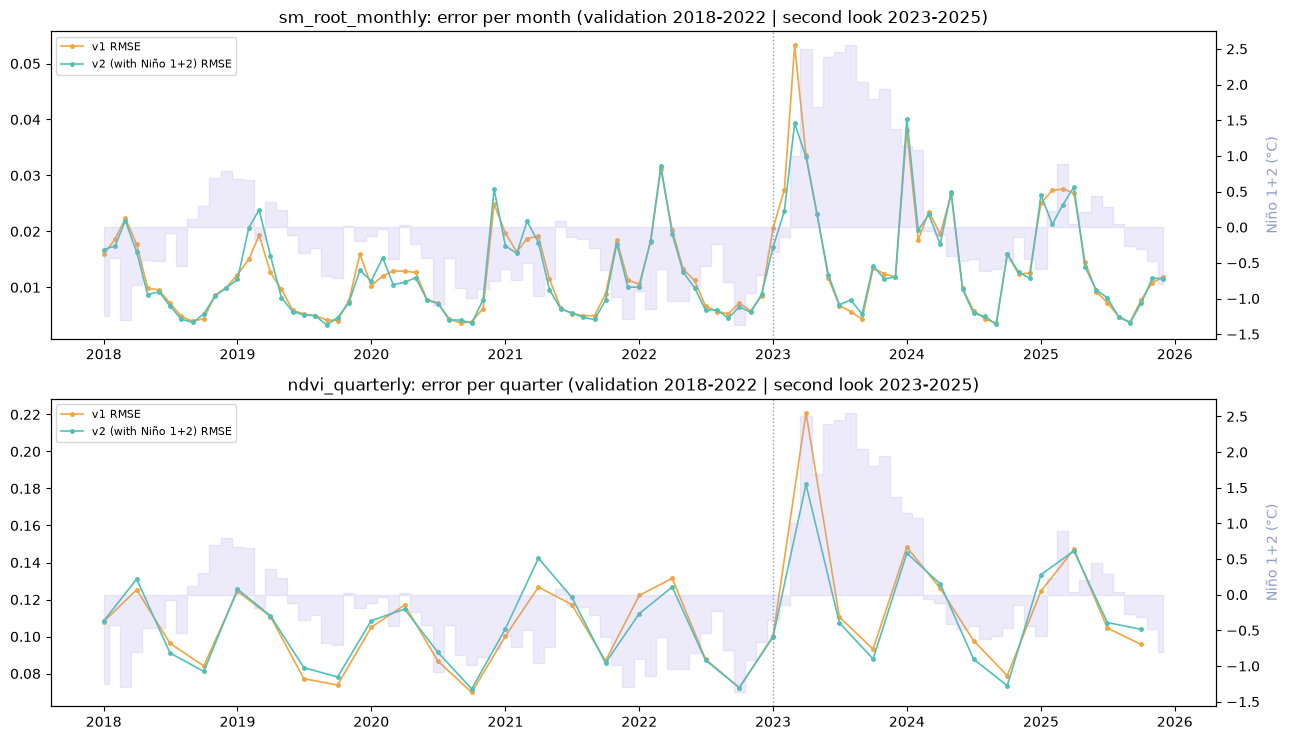

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7.5))
for a, n in zip(ax, NAMES):
    parts = []
    for src in (VAL, TEST):
        r, y, p = src[n]
        parts.append(pd.DataFrame({"t": period_key(r).values, "e1": (p["v1"] - y) ** 2, "e2": (p["v2"] - y) ** 2}))
    g = pd.concat(parts).groupby("t")[["e1", "e2"]].mean() ** 0.5
    a.plot(g.index, g.e1, color="#F2A541", marker="o", ms=2.5, lw=1.2, label="v1 RMSE")
    a.plot(g.index, g.e2, color="#4FC1B6", marker="o", ms=2.5, lw=1.2, label="v2 (with Niño 1+2) RMSE")
    a.axvline(pd.Timestamp("2023-01-01"), color="#8C9BC4", ls=":", lw=1)
    b = a.twinx(); s = nm[(nm.date >= "2018-01-01") & (nm.date <= "2025-12-01")]
    b.fill_between(s.date, 0, s.nino12_anom, color="#A99BE8", alpha=0.2, step="mid"); b.set_ylabel("Niño 1+2 (°C)", color="#8C9BC4")
    a.set_title(f"{n}: error per {'month' if n.startswith('sm') else 'quarter'} (validation 2018-2022 | second look 2023-2025)")
    a.legend(loc="upper left", fontsize=8)
plt.tight_layout(); fig.savefig(ART / "v2_nino_error_timeline.png", dpi=110); plt.show()

## 9. Save (v2 candidates only; the final v1 package is untouched)

In [13]:
assert all(D.sha256(ML_DIR / "artifacts" / "final_model" / n / "model.ubj") == V1_SHA[n] for n in NAMES)
for n in NAMES:
    out = ART / n; out.mkdir(exist_ok=True)
    V2[n]["model"].save_model(out / "model.ubj")
    (out / "preprocessing.json").write_text(json.dumps({"feature_names_in_order": V2[n]["features"], "imputation": "none (XGBoost native missing)",
                                                        "scaling": "none", "training_feature_bounds": V2[n]["bounds"]}, indent=1))
    (out / "metadata.json").write_text(json.dumps({
        "name": n, "version": "v2-nino (candidate, not adopted)", "sha256": D.sha256(out / "model.ubj"),
        "target": V1[n]["card"]["target"], "new_features": NEW[n], "hyperparameters": V2[n]["params"], "trees": V2[n]["trees"],
        "training_years": "1998-2017 (early stopping on 2016-2017, refit on 1998-2017)", "internal_es_rmse_2016_2017": V2[n]["internal_es_rmse"],
        "nino12_source": NINO_INFO, "validation_decision": DECISION[n], "criteria": CRIT[n].to_dict("records"),
        "second_look_2023_2025": {"metrics": TCI[n].to_dict("records"), "aci": ACI[ACI.model == n].to_dict("records"), "inputs_outside_range": OOD[n]},
        "reference_v1_sha256": V1_SHA[n], "versions": {"python": platform.python_version(), "xgboost": xgb.__version__, "pandas": pd.__version__}},
        indent=1, default=str))
    CI[n].to_csv(out / "validation_metrics_ci.csv", index=False); CRIT[n].to_csv(out / "criteria.csv", index=False)
    TCI[n].to_csv(out / "second_look_2023_2025_metrics_ci.csv", index=False)
FOC.to_csv(ART / "second_look_focus_periods.csv", index=False); ACI.to_csv(ART / "second_look_aci_coverage.csv", index=False)
IMP.to_csv(ART / "nino_feature_use.csv", index=False)
(ART / "summary.json").write_text(json.dumps({"decision": DECISION, "nino12": NINO_INFO, "status": "candidate; v1 stays the standard model"}, indent=1, default=str))
for f in sorted(ART.rglob("*")):
    if f.is_file(): print(f.relative_to(ML_DIR))

artifacts/v2_nino_models/ndvi_quarterly/criteria.csv
artifacts/v2_nino_models/ndvi_quarterly/metadata.json
artifacts/v2_nino_models/ndvi_quarterly/model.ubj
artifacts/v2_nino_models/ndvi_quarterly/preprocessing.json
artifacts/v2_nino_models/ndvi_quarterly/second_look_2023_2025_metrics_ci.csv
artifacts/v2_nino_models/ndvi_quarterly/validation_metrics_ci.csv
artifacts/v2_nino_models/nino_feature_use.csv
artifacts/v2_nino_models/second_look_aci_coverage.csv
artifacts/v2_nino_models/second_look_focus_periods.csv
artifacts/v2_nino_models/sm_root_monthly/criteria.csv
artifacts/v2_nino_models/sm_root_monthly/metadata.json
artifacts/v2_nino_models/sm_root_monthly/model.ubj
artifacts/v2_nino_models/sm_root_monthly/preprocessing.json
artifacts/v2_nino_models/sm_root_monthly/second_look_2023_2025_metrics_ci.csv
artifacts/v2_nino_models/sm_root_monthly/validation_metrics_ci.csv
artifacts/v2_nino_models/summary.json
artifacts/v2_nino_models/v2_nino_error_timeline.png
